# 07. 종합분석 — 페르소나 × 추천확률

**입력**: `dataSets/starfield_analysis.csv`, `dataSets/reviews_for_embedding.csv`, `dataSets/추천확률.csv` (05b), `dataSets/유저군집.csv` (06)
**출력**: `out/07-1_추천확률_평균.png`, `out/07-2_구간비율.png`, `out/07-3_불일치_플레이시간.png`, `out/07-4_단계별_추천확률_평균.png`

05b의 추천확률과 06의 페르소나를 처음 결합한다.
- 플레이시간은 극단값이 있어서 **중앙값**으로 비교한다.
- 추천확률은 0~1 범위이고 보정된 확률이라 **평균**으로 비교한다 (평균 = 그 집단의 기대 긍정률).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

os.makedirs('out', exist_ok=True)

# 한글 폰트: 폴더에 있는 폰트 파일을 쓰고, 없으면 맥 기본 폰트(AppleGothic)를 쓴다
FONT_FILE = 'helpers/fonts/NotoSansKR-Regular.ttf'
if os.path.exists(FONT_FILE):
    font_manager.fontManager.addfont(FONT_FILE)                                   # 폰트 파일 등록
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=FONT_FILE).get_name()   # 파일 안의 폰트 이름을 읽어 지정
else:
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

PERSONAS = ['하드 리뷰어', '초기 리뷰어', '라이트 리뷰어']
COLOR = {'하드 리뷰어': '#4C72B0', '초기 리뷰어': '#DD8452', '라이트 리뷰어': '#55A868'}
C_POS = '#4C72B0'
C_NEG = '#C44E52'
C_MID = '#A0A0A0'

## 데이터 준비

In [2]:
meta = pd.read_csv('dataSets/starfield_analysis.csv', low_memory=False)
pop = pd.read_csv('dataSets/reviews_for_embedding.csv', usecols=['steamid'])
prob = pd.read_csv('dataSets/추천확률.csv')
persona = pd.read_csv('dataSets/유저군집.csv')

# 06의 군집 이름을 PPT 표기로 바꾼다
name_map = {'하드코어 리뷰어': '하드 리뷰어', '초반 리뷰어': '초기 리뷰어', '라이트 몰입형': '라이트 리뷰어'}
persona['페르소나'] = persona['군집'].map(name_map)

df = meta.merge(pop, on='steamid', how='inner')
df = df.merge(prob, on='steamid', how='inner')
df = df.merge(persona[['steamid', '페르소나']], on='steamid', how='inner')
print('분석 대상', len(df), '건')

# 플레이시간은 상위 0.5% 상한값 대체 (04·06과 같은 처리)
for col in ['playtime_at_review_min', 'playtime_forever_min']:
    cap = df[col].quantile(0.995)
    df[col] = df[col].clip(upper=cap)
df['리뷰시점h'] = df['playtime_at_review_min'] / 60
df['리뷰이후h'] = (df['playtime_forever_min'] - df['playtime_at_review_min']) / 60

# 추천확률 구간: 부정 < 0.3 ≤ 중간 < 0.7 ≤ 긍정
df['구간'] = pd.cut(df['추천확률'], [-0.01, 0.3, 0.7, 1.01], right=False, labels=['부정', '중간', '긍정'])
print(df['구간'].value_counts().sort_index())

# 버튼과 글이 어긋나는 리뷰
df['불일치 추천'] = (df['voted_up'] == True) & (df['추천확률'] < 0.3)      # 추천 버튼 + 부정 글
df['불일치 비추천'] = (df['voted_up'] == False) & (df['추천확률'] >= 0.7)  # 비추천 버튼 + 긍정 글

분석 대상 70915 건
구간
부정    24434
중간    11106
긍정    35375
Name: count, dtype: int64


## 7-1. 누가 만족/불만족했나 — 페르소나별 추천확률 평균

In [3]:
stat = df.groupby('페르소나')['추천확률'].agg(['mean', 'median', 'size']).loc[PERSONAS]
stat['긍정률'] = df.groupby('페르소나')['voted_up'].mean()
print(stat.round(3))

light_vs_hard = stat.loc['라이트 리뷰어', 'mean'] - stat.loc['하드 리뷰어', 'mean']
early_vs_hard = stat.loc['초기 리뷰어', 'mean'] - stat.loc['하드 리뷰어', 'mean']
print(f'평균 차이: 라이트 − 하드 {light_vs_hard:+.3f}, 초기 − 하드 {early_vs_hard:+.3f}')

# 부트스트랩: 평균과 중앙값 중 어느 쪽이 안정적인지 (표준오차 비교)
rng = np.random.default_rng(3217)
for name in PERSONAS:
    values = df.loc[df['페르소나'] == name, '추천확률'].values
    means = []
    medians = []
    for _ in range(200):
        resample = rng.choice(values, len(values))   # 복원추출
        means.append(resample.mean())
        medians.append(np.median(resample))
    print(f'{name}: 표준오차 평균 {np.std(means):.4f} / 중앙값 {np.std(medians):.4f}')

          mean  median   size    긍정률
페르소나                                
하드 리뷰어   0.567   0.680  26300  0.574
초기 리뷰어   0.505   0.508  20805  0.478
라이트 리뷰어  0.635   0.834  23810  0.650
평균 차이: 라이트 − 하드 +0.068, 초기 − 하드 -0.062
하드 리뷰어: 표준오차 평균 0.0024 / 중앙값 0.0066
초기 리뷰어: 표준오차 평균 0.0029 / 중앙값 0.0108
라이트 리뷰어: 표준오차 평균 0.0024 / 중앙값 0.0042


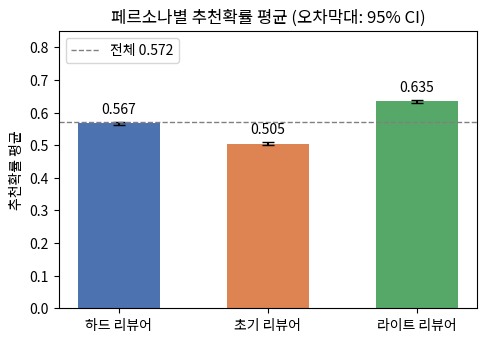

In [4]:
se = df.groupby('페르소나')['추천확률'].sem().loc[PERSONAS]   # 표준오차
means = stat['mean']

fig, ax = plt.subplots(figsize=(5.4, 3.6))
ax.bar(PERSONAS, means, width=0.55, color=[COLOR[p] for p in PERSONAS], yerr=1.96 * se, capsize=4)
for i, name in enumerate(PERSONAS):
    ax.text(i, means[name] + 0.03, f'{means[name]:.3f}', ha='center', fontsize=10, fontweight='bold')
overall = df['추천확률'].mean()
ax.axhline(overall, ls='--', color='gray', lw=1, label=f'전체 {overall:.3f}')
ax.set_ylabel('추천확률 평균')
ax.set_ylim(0, 0.85)
ax.set_title('페르소나별 추천확률 평균 (오차막대: 95% CI)')
ax.legend(loc='upper left')
fig.savefig('out/07-1_추천확률_평균.png', dpi=150, bbox_inches='tight')
plt.show()

## 7-2. 얼마나 명확하게 평가했나 — 추천확률 구간 비율

구간         부정    중간    긍정
페르소나                     
하드 리뷰어   34.2  16.7  49.0
초기 리뷰어   41.6  16.4  42.1
라이트 리뷰어  28.5  13.9  57.6


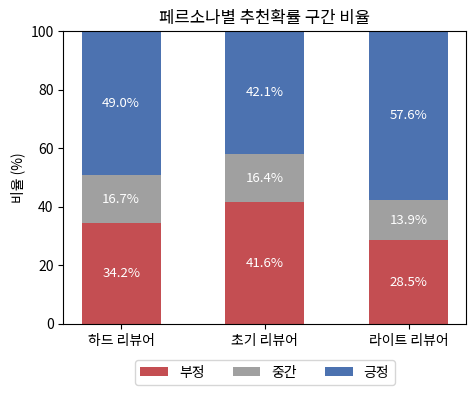

In [5]:
share = pd.crosstab(df['페르소나'], df['구간'], normalize='index') * 100
share = share.loc[PERSONAS]
print(share.round(1))

fig, ax = plt.subplots(figsize=(5.2, 3.8))
bottom = np.zeros(3)
for seg, color in [('부정', C_NEG), ('중간', C_MID), ('긍정', C_POS)]:
    values = share[seg].values
    ax.bar(PERSONAS, values, bottom=bottom, color=color, width=0.55, label=seg)
    for i in range(3):
        ax.text(i, bottom[i] + values[i] / 2, f'{values[i]:.1f}%', ha='center', va='center', color='white', fontsize=9.5, fontweight='bold')
    bottom = bottom + values
ax.set_ylim(0, 100)
ax.set_ylabel('비율 (%)')
ax.set_title('페르소나별 추천확률 구간 비율')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))
fig.savefig('out/07-2_구간비율.png', dpi=150, bbox_inches='tight')
plt.show()

## 7-3. 불일치 케이스 — 건수·비율과 플레이시간 비교

불일치 추천·비추천을 같은 버튼을 누른 나머지(일반 추천·일반 비추천)와 플레이시간 중앙값으로 비교한다.

In [6]:
mis = df.groupby('페르소나').agg(
    불일치추천=('불일치 추천', 'sum'), 불일치추천비율=('불일치 추천', 'mean'),
    불일치비추천=('불일치 비추천', 'sum'), 불일치비추천비율=('불일치 비추천', 'mean'),
).loc[PERSONAS]
mis['불일치추천비율'] = mis['불일치추천비율'] * 100
mis['불일치비추천비율'] = mis['불일치비추천비율'] * 100
print(mis.round(2))

# 네 그룹으로 나눈다
df['그룹'] = '일반 비추천'
df.loc[df['voted_up'] == True, '그룹'] = '일반 추천'
df.loc[df['불일치 추천'], '그룹'] = '불일치 추천'
df.loc[df['불일치 비추천'], '그룹'] = '불일치 비추천'

play = df.groupby(['페르소나', '그룹'])[['리뷰시점h', '리뷰이후h']].median().round(1)
print()
print('그룹별 플레이시간 중앙값 (h)')
print(play.unstack('그룹').loc[PERSONAS])

         불일치추천  불일치추천비율  불일치비추천  불일치비추천비율
페르소나                                     
하드 리뷰어     734     2.79     775      2.95
초기 리뷰어     514     2.47     719      3.46
라이트 리뷰어    527     2.21     514      2.16

그룹별 플레이시간 중앙값 (h)
          리뷰시점h                       리뷰이후h                    
그룹      불일치 비추천 불일치 추천 일반 비추천 일반 추천 불일치 비추천 불일치 추천 일반 비추천 일반 추천
페르소나                                                           
하드 리뷰어     54.1   61.1   59.4  53.0     6.7   23.7    1.9  39.9
초기 리뷰어      7.0    7.2    6.8  10.0     1.4   23.4    1.0  35.4
라이트 리뷰어    49.6   56.7   58.2  52.1     4.8   31.6    2.7  49.0


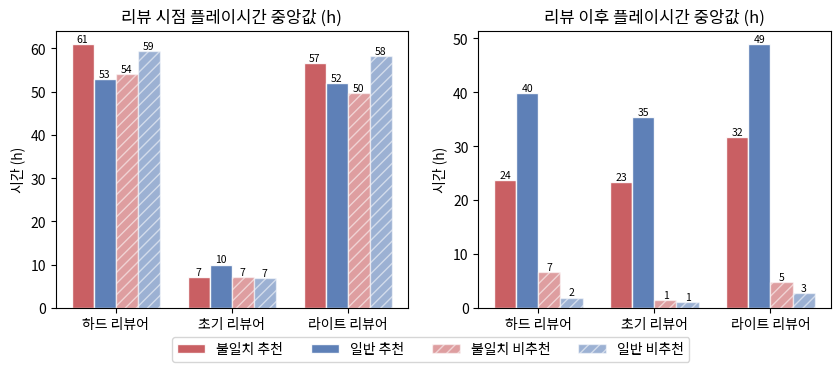

In [7]:
GROUPS = ['불일치 추천', '일반 추천', '불일치 비추천', '일반 비추천']
GROUP_COLOR = {'불일치 추천': C_NEG, '일반 추천': C_POS, '불일치 비추천': C_NEG, '일반 비추천': C_POS}
GROUP_HATCH = {'불일치 추천': None, '일반 추천': None, '불일치 비추천': '///', '일반 비추천': '///'}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
x = np.arange(3)
width = 0.19
for ax, col, title in zip(axes, ['리뷰시점h', '리뷰이후h'], ['리뷰 시점 플레이시간 중앙값 (h)', '리뷰 이후 플레이시간 중앙값 (h)']):
    for k, group in enumerate(GROUPS):
        values = [play.loc[(p, group), col] for p in PERSONAS]
        alpha = 0.9 if GROUP_HATCH[group] is None else 0.55
        bars = ax.bar(x + (k - 1.5) * width, values, width, color=GROUP_COLOR[group], alpha=alpha,
                      hatch=GROUP_HATCH[group], label=group, edgecolor='white')
        ax.bar_label(bars, fmt='%.0f', fontsize=7.5)
    ax.set_xticks(x)
    ax.set_xticklabels(PERSONAS)
    ax.set_title(title)
    ax.set_ylabel('시간 (h)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, loc='lower center', bbox_to_anchor=(0.5, -0.06))
fig.savefig('out/07-3_불일치_플레이시간.png', dpi=150, bbox_inches='tight')
plt.show()

## 7-4. 어느 지점에서 실망했나 — 진행 단계별 추천확률 평균

리뷰 시점 메인 퀘스트 단계(0~10)별 평균. 초기 리뷰어는 5단계 이후 리뷰가 몇십 건뿐이라 n < 30인 점은 빈 원으로 표시하고 해석을 보류한다.

단계별 추천확률 평균
페르소나             하드 리뷰어  초기 리뷰어  라이트 리뷰어
stage_at_review                         
0                 0.585   0.543    0.636
1                 0.521   0.447    0.658
2                 0.571   0.512    0.643
3                 0.573   0.536    0.641
4                 0.574   0.607    0.644
5                 0.551   0.550    0.629
6                 0.571   0.629    0.643
7                 0.547   0.460    0.614
8                 0.526   0.686    0.661
9                 0.574   0.509    0.638
10                0.562   0.553    0.621

단계별 n
페르소나             하드 리뷰어  초기 리뷰어  라이트 리뷰어
stage_at_review                         
0                   295    1949      259
1                   195    3852      213
2                  8836   13933     8017
3                  3106     724     2709
4                  2155     195     1970
5                   957      74      914
6                  1245      33     1133
7                  1154      19     1165
8                   247       1      2

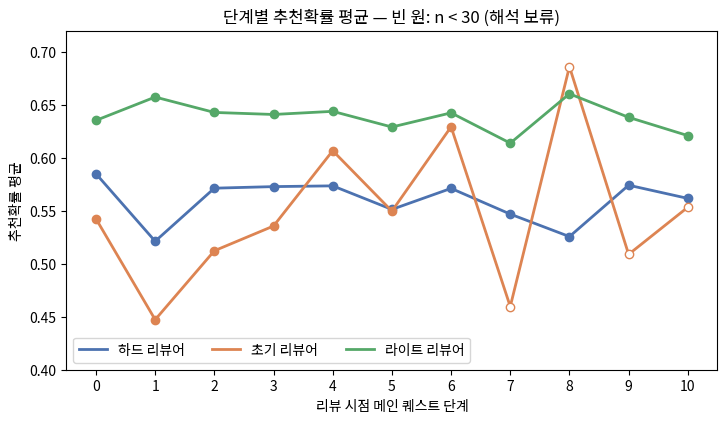

In [8]:
stage_mean = df.pivot_table(index='stage_at_review', columns='페르소나', values='추천확률', aggfunc='mean')[PERSONAS]
stage_n = df.pivot_table(index='stage_at_review', columns='페르소나', values='추천확률', aggfunc='size')[PERSONAS]
print('단계별 추천확률 평균')
print(stage_mean.round(3))
print()
print('단계별 n')
print(stage_n)

stages = stage_mean.index.values
fig, ax = plt.subplots(figsize=(8.4, 4.4))
for name in PERSONAS:
    means = stage_mean[name].values
    counts = stage_n[name].values
    ax.plot(stages, means, color=COLOR[name], lw=2, label=name)
    for s, m, n in zip(stages, means, counts):
        if n >= 30:
            ax.plot(s, m, marker='o', color=COLOR[name], ms=6)                      # 채운 원
        else:
            ax.plot(s, m, marker='o', mfc='white', mec=COLOR[name], ms=6)           # 빈 원 = n < 30
ax.set_xlabel('리뷰 시점 메인 퀘스트 단계')
ax.set_ylabel('추천확률 평균')
ax.set_xticks(stages)
ax.set_ylim(0.4, 0.72)
ax.set_title('단계별 추천확률 평균 — 빈 원: n < 30 (해석 보류)')
ax.legend(loc='lower left', ncol=3)
fig.savefig('out/07-4_단계별_추천확률_평균.png', dpi=150, bbox_inches='tight')
plt.show()

## 7-5. 리뷰 이후엔 어떻게 됐나 — 리뷰 이후 플레이시간

이탈 비율 = 리뷰 이후 플레이시간이 10시간 미만인 비율 (06의 표와 같은 정의).

In [9]:
df['이탈'] = df['리뷰이후h'] < 10


def after_table(key, order):
    """key(페르소나 또는 구간)별 유저 수, 리뷰 이후 플레이 중앙값, 이탈 비율 표"""
    t = df.groupby(key, observed=True).agg(유저수=('steamid', 'size'), 중앙값h=('리뷰이후h', 'median'), 이탈비율=('이탈', 'mean'))
    t = t.loc[order]
    t.loc['전체'] = [len(df), df['리뷰이후h'].median(), df['이탈'].mean()]
    t['유저수'] = t['유저수'].astype(int)
    return t


print('페르소나별')
print(after_table('페르소나', PERSONAS).round(3))
print()
print('추천확률 구간별')
print(after_table('구간', ['부정', '중간', '긍정']).round(3))

페르소나별
           유저수    중앙값h   이탈비율
페르소나                         
하드 리뷰어   26300  20.300  0.407
초기 리뷰어   20805   9.683  0.503
라이트 리뷰어  23810  28.858  0.341
전체       70915  19.717  0.413

추천확률 구간별
      유저수    중앙값h   이탈비율
구간                      
부정  24434   1.717  0.648
중간  11106  14.367  0.452
긍정  35375  41.317  0.238
전체  70915  19.717  0.413


## 7-6. 한국어 리뷰어 (후속 과제 근거)

language는 Steam 클라이언트 언어 설정이다. 페르소나별로 한국어 설정 리뷰어와 나머지의 추천확률 평균을 비교한다.

In [10]:
df['한국어'] = df['language'] == 'koreana'
rows = []
for name in PERSONAS:
    g = df[df['페르소나'] == name]
    ko = g[g['한국어']]['추천확률'].mean()
    not_ko = g[~g['한국어']]['추천확률'].mean()
    rows.append({'페르소나': name, '한국어 제외': not_ko, '한국어': ko, '격차(%p)': (ko - not_ko) * 100, '한국어 n': g['한국어'].sum()})
print(pd.DataFrame(rows).set_index('페르소나').round(3))

         한국어 제외    한국어  격차(%p)  한국어 n
페르소나                                 
하드 리뷰어    0.567  0.517  -5.027    212
초기 리뷰어    0.506  0.423  -8.317    213
라이트 리뷰어   0.637  0.450 -18.701    185
